# Aviation Accidents: Data Analysis

**Client:** an airline / airplane insurer. **Goal:** recommend professionally built airplane makes/models (potentially still in service, so 1983 onward) with low rates of destruction and low likelihood of fatal or serious injuries, with **separate recommendations for small vs. large aircraft**, plus at least two general factors that influence outcomes.

**Metrics (built in the cleaning notebook)**
- `fatal_serious_frac`: (fatal + serious injuries) / persons aboard, per accident
- `destroyed`: 1 if the aircraft was destroyed

**How we keep claims statistically robust**
- Minimum sample sizes before a group is ranked (stated at every step).
- 95% confidence intervals on every mean/proportion (bootstrap for the injury fraction, Wilson for destroyed rates).
- Hypothesis tests (chi-square, Mann-Whitney U, Kruskal-Wallis) for factor comparisons.

**Important caveat:** the data contains only *accidents*. There are no flight-hour or departure counts, so every rate here is "given that an accident happened, how bad was it?", **not** "how likely is an accident?". Safe designs are judged on survivability and damage, not accident frequency.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import os
os.makedirs('images', exist_ok=True)
def save(name):
    plt.savefig(f'images/{name}.png', dpi=130, bbox_inches='tight')

sns.set_theme(style='whitegrid', context='notebook')
rng = np.random.default_rng(42)

def boot_ci(x, n_boot=2000, alpha=0.05):
    """Bootstrap CI of the mean."""
    x = np.asarray(x, dtype=float)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [100*alpha/2, 100*(1-alpha/2)])

def wilson(k, n, z=1.96):
    """Wilson score interval for a proportion."""
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / d
    h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return max(0.0, c - h), min(1.0, c + h)

## Load the cleaned data

In [2]:
df = pd.read_csv('data/cleaned_aviation.csv', parse_dates=['Event.Date'])
print(df.shape)
df.head()

(55798, 20)


,Event.Id,Event.Date,Aircraft.damage,plane_type,Make,Model,fatal_serious_frac,destroyed,Total.Minor.Injuries,total_passengers,fatal_serious,Total.Uninjured,Total.Fatal.Injuries,Total.Serious.Injuries,Country,Number.of.Engines,Weather.Condition,Engine.Type,Purpose.of.flight,Broad.phase.of.flight
0,20001214X42095,1983-01-01,Substantial,CESSNA 182P,CESSNA,182P,0.0,0,1.0,4.0,0.0,3.0,0.0,0.0,United States,1.0,VMC,Reciprocating,Personal,Approach
1,20001214X42067,1983-01-01,Substantial,CESSNA 182RG,CESSNA,182RG,0.0,0,0.0,2.0,0.0,2.0,0.0,0.0,United States,1.0,VMC,Reciprocating,Personal,Landing
2,20001214X42063,1983-01-01,Substantial,CESSNA 182P,CESSNA,182P,0.0,0,0.0,1.0,0.0,1.0,0.0,0.0,United States,1.0,VMC,Reciprocating,Personal,Takeoff
3,20001214X42018,1983-01-01,Substantial,PIPER PA28R200,PIPER,PA28R200,0.0,0,2.0,2.0,0.0,0.0,0.0,0.0,United States,1.0,VMC,Reciprocating,Personal,Approach
4,20001214X41951,1983-01-01,Substantial,CESSNA 140,CESSNA,140,0.0,0,0.0,2.0,0.0,2.0,0.0,0.0,United States,1.0,VMC,Reciprocating,Instructional,Landing


In [3]:
df[['total_passengers', 'fatal_serious_frac', 'destroyed']].describe()

,total_passengers,fatal_serious_frac,destroyed
count,55798.000000,55798.000000,55798.000000
mean,4.403921,0.270313,0.205778
std,21.225272,0.429031,0.404273
min,1.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000
75%,2.000000,0.666667,0.000000
max,588.000000,1.000000,1.000000


## Separating small and large airplanes (threshold = 20 persons aboard)
A naive rule such as "the maximum number aboard in any accident is at least 20" is fragile: one mis-keyed record turns a 4-seat Piper into a "large" plane (e.g. 542 Piper PA-28-181 accidents have only 1-5 aboard in typical cases). Instead we classify each **plane type** (`plane_type` = make + model) by how its accidents typically look:

> A plane type is **Large** if at least **25%** of its accident records have **20 or more persons aboard**; otherwise it is **Small**.

This puts 19-seat commuter turboprops like the Beech 1900 in Small, and airliners (even those with some cargo-flight accidents, like the 747) in Large.

In [4]:
df['ge20'] = df['total_passengers'] >= 20
type_share = df.groupby('plane_type')['ge20'].mean()
df['size_class'] = np.where(df['plane_type'].map(type_share) >= 0.25, 'Large', 'Small')

print(df['size_class'].value_counts())
print()
print(df.groupby('size_class')['total_passengers'].describe().round(1))
df.groupby('size_class')[['fatal_serious_frac', 'destroyed']].mean().round(3)

size_class
Small    54656
Large     1142
Name: count, dtype: int64

              count   mean   std  min   25%    50%    75%    max
size_class                                                      
Large        1142.0  116.8  94.0  1.0  44.0  110.0  161.0  588.0
Small       54656.0    2.1   2.4  1.0   1.0    2.0    2.0  267.0


,fatal_serious_frac,destroyed
size_class,,
Large,0.107,0.114
Small,0.274,0.208


## Explore safety metrics across makes

**Minimum sample rules:** small makes need at least **50** accident records in the Small group (this matches the cleaning threshold). Large makes are rarer, so we require at least **20** records in the Large group to be ranked. Makes below these thresholds are excluded from rankings because their averages are unreliable.

In [5]:
def make_table(data, min_n):
    rows = []
    for make, g in data.groupby('Make'):
        if len(g) < min_n:
            continue
        lo, hi = boot_ci(g['fatal_serious_frac'])
        dl, dh = wilson(g['destroyed'].sum(), len(g))
        rows.append(dict(Make=make, n=len(g), n_types=g['plane_type'].nunique(),
                         mean_fs=g['fatal_serious_frac'].mean(), fs_lo=lo, fs_hi=hi,
                         destroyed=g['destroyed'].mean(), d_lo=dl, d_hi=dh))
    return pd.DataFrame(rows).sort_values('mean_fs').reset_index(drop=True)

small = df[df['size_class'] == 'Small']
large = df[df['size_class'] == 'Large']
small_makes = make_table(small, 50)
large_makes = make_table(large, 20)
print('Small makes ranked:', len(small_makes), '| Large makes ranked:', len(large_makes))
print('Records: small', len(small), 'large', len(large))

Small makes ranked: 42 | Large makes ranked: 6
Records: small 54656 large 1142


### Mean fatal/serious fraction: 15 lowest makes in each group
Error bars are 95% bootstrap confidence intervals.

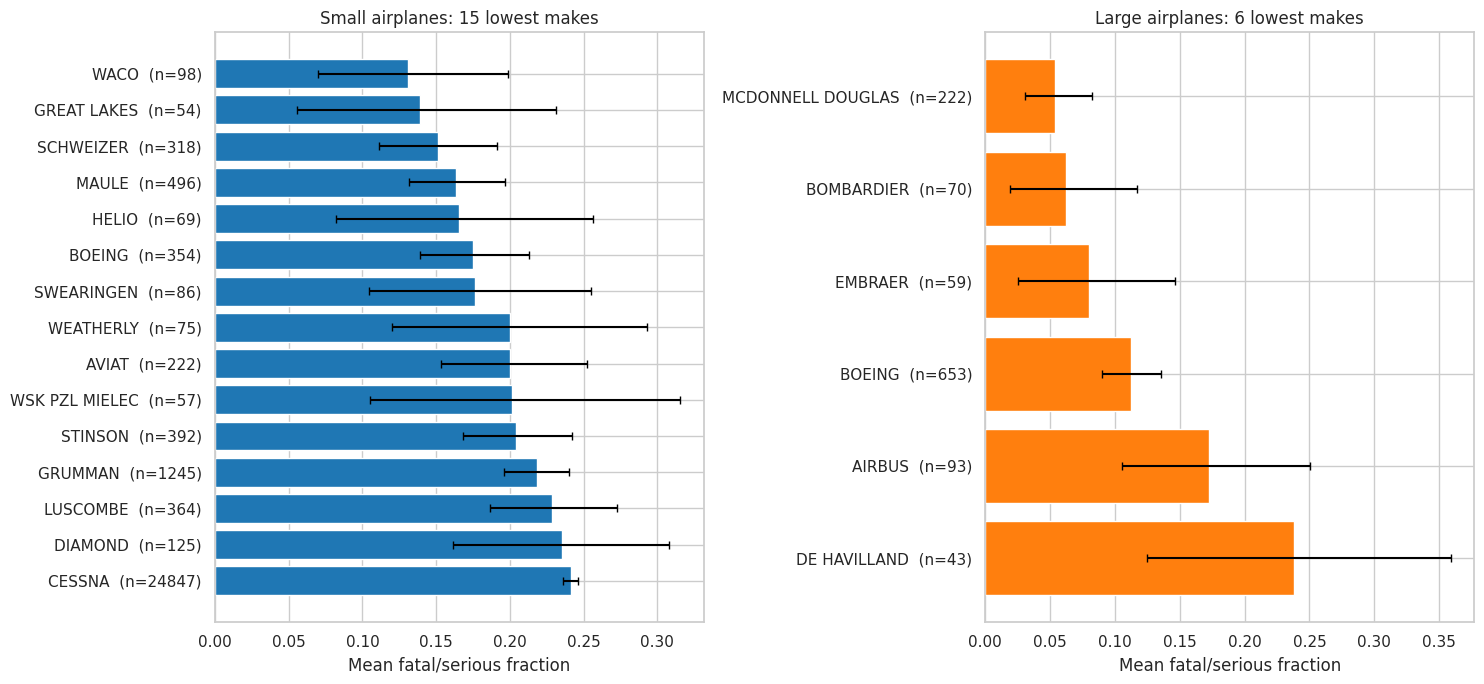

,Make,n,n_types,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,WACO,98,20,0.131,0.070,0.199,0.102,0.056,0.178
1,GREAT LAKES,54,3,0.139,0.056,0.231,0.111,0.052,0.222
2,SCHWEIZER,318,6,0.151,0.111,0.191,0.173,0.135,0.218
3,MAULE,496,39,0.163,0.131,0.197,0.093,0.070,0.121
4,HELIO,69,7,0.166,0.082,0.256,0.159,0.091,0.263
5,BOEING,354,55,0.175,0.139,0.213,0.124,0.094,0.163
6,SWEARINGEN,86,11,0.176,0.104,0.255,0.151,0.091,0.242
7,WEATHERLY,75,4,0.200,0.120,0.293,0.213,0.136,0.319
8,AVIAT,222,17,0.200,0.153,0.252,0.063,0.038,0.103
9,WSK PZL MIELEC,57,4,0.202,0.105,0.316,0.228,0.138,0.352


,Make,n,n_types,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,MCDONNELL DOUGLAS,222,23,0.054,0.031,0.082,0.086,0.055,0.130
1,BOMBARDIER,70,9,0.062,0.019,0.117,0.057,0.022,0.138
2,EMBRAER,59,18,0.080,0.026,0.146,0.051,0.017,0.139
3,BOEING,653,107,0.113,0.090,0.135,0.116,0.094,0.143
4,AIRBUS,93,29,0.172,0.105,0.251,0.172,0.109,0.261
5,DE HAVILLAND,43,5,0.238,0.124,0.359,0.256,0.149,0.402


In [6]:
def bar_with_ci(ax, tbl, val, lo, hi, color, title, xlabel):
    t = tbl.iloc[::-1]
    ax.barh(t['Make'] + '  (n=' + t['n'].astype(str) + ')', t[val], color=color,
            xerr=[t[val] - t[lo], t[hi] - t[val]], capsize=3, ecolor='black')
    ax.set_title(title); ax.set_xlabel(xlabel)

top_small = small_makes.head(15)
top_large = large_makes.head(15)
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
bar_with_ci(axes[0], top_small, 'mean_fs', 'fs_lo', 'fs_hi', 'tab:blue',
            'Small airplanes: 15 lowest makes', 'Mean fatal/serious fraction')
bar_with_ci(axes[1], top_large, 'mean_fs', 'fs_lo', 'fs_hi', 'tab:orange',
            f'Large airplanes: {len(top_large)} lowest makes', 'Mean fatal/serious fraction')
plt.tight_layout(); save('makes_injury'); plt.show()
display(top_small.round(3)); display(top_large.round(3))

**Distribution of injury rates: small makes** (violin plot, 10 lowest-mean makes)

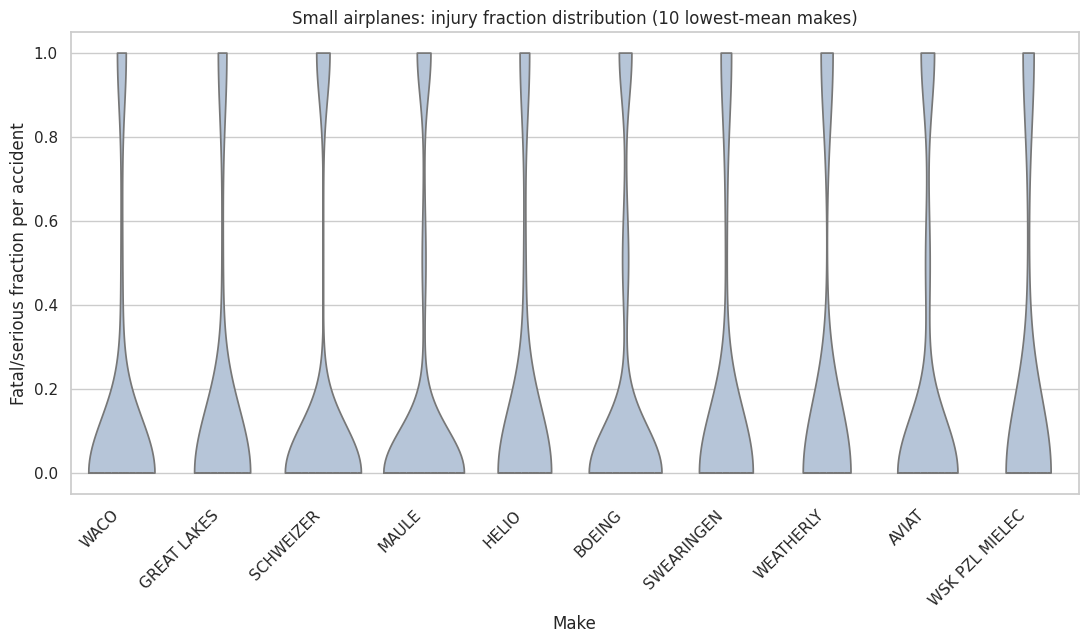

,n,mean,median,pct_zero,pct_all
Make,,,,,
WACO,98,0.131,0.0,0.847,0.112
GREAT LAKES,54,0.139,0.0,0.852,0.130
SCHWEIZER,318,0.151,0.0,0.846,0.148
MAULE,496,0.163,0.0,0.810,0.137
HELIO,69,0.166,0.0,0.797,0.145
BOEING,354,0.175,0.0,0.782,0.136
SWEARINGEN,86,0.176,0.0,0.802,0.151
WEATHERLY,75,0.200,0.0,0.800,0.200
AVIAT,222,0.200,0.0,0.770,0.171


In [7]:
order = small_makes.head(10)['Make'].tolist()
plt.figure(figsize=(13, 6))
sns.violinplot(data=small[small['Make'].isin(order)], x='Make', y='fatal_serious_frac',
               order=order, cut=0, inner='quartile', color='lightsteelblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Fatal/serious fraction per accident'); plt.title('Small airplanes: injury fraction distribution (10 lowest-mean makes)')
save('small_violin'); plt.show()
small[small['Make'].isin(order)].groupby('Make')['fatal_serious_frac'].agg(
    n='size', mean='mean', median='median', pct_zero=lambda s: (s == 0).mean(), pct_all=lambda s: (s == 1).mean()).loc[order].round(3)

**Distribution of injury rates: large makes** (strip plot, 10 lowest-mean makes)

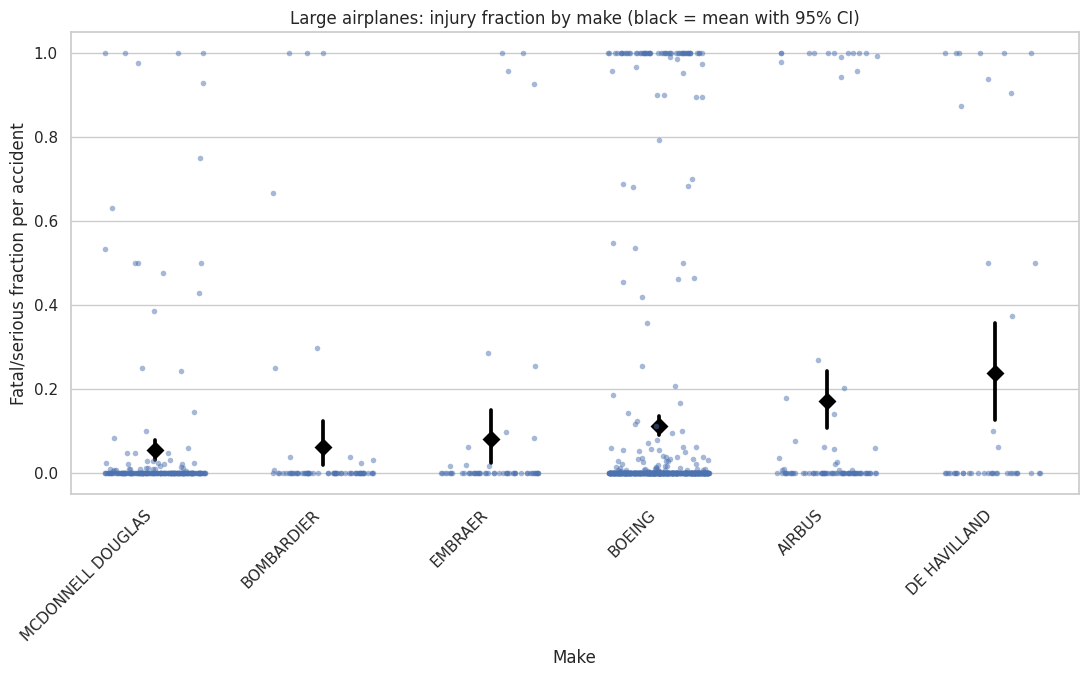

,n,mean,median,pct_zero,pct_all
Make,,,,,
MCDONNELL DOUGLAS,222,0.054,0.0,0.784,0.018
BOMBARDIER,70,0.062,0.0,0.843,0.043
EMBRAER,59,0.080,0.0,0.797,0.034
BOEING,653,0.113,0.0,0.795,0.083
AIRBUS,93,0.172,0.0,0.677,0.108
DE HAVILLAND,43,0.238,0.0,0.674,0.140


In [8]:
order_l = large_makes.head(10)['Make'].tolist()
plt.figure(figsize=(13, 6))
sns.stripplot(data=large[large['Make'].isin(order_l)], x='Make', y='fatal_serious_frac',
              order=order_l, jitter=0.3, alpha=0.5, size=4)
sns.pointplot(data=large[large['Make'].isin(order_l)], x='Make', y='fatal_serious_frac',
              order=order_l, linestyle='none', color='black', markers='D', errorbar=('ci', 95))
plt.xticks(rotation=45, ha='right')
plt.ylabel('Fatal/serious fraction per accident'); plt.title('Large airplanes: injury fraction by make (black = mean with 95% CI)')
save('large_strip'); plt.show()
large[large['Make'].isin(order_l)].groupby('Make')['fatal_serious_frac'].agg(
    n='size', mean='mean', median='median', pct_zero=lambda s: (s == 0).mean(), pct_all=lambda s: (s == 1).mean()).loc[order_l].round(3)

**Rate of aircraft destruction by make** (15 lowest, Wilson 95% CI)

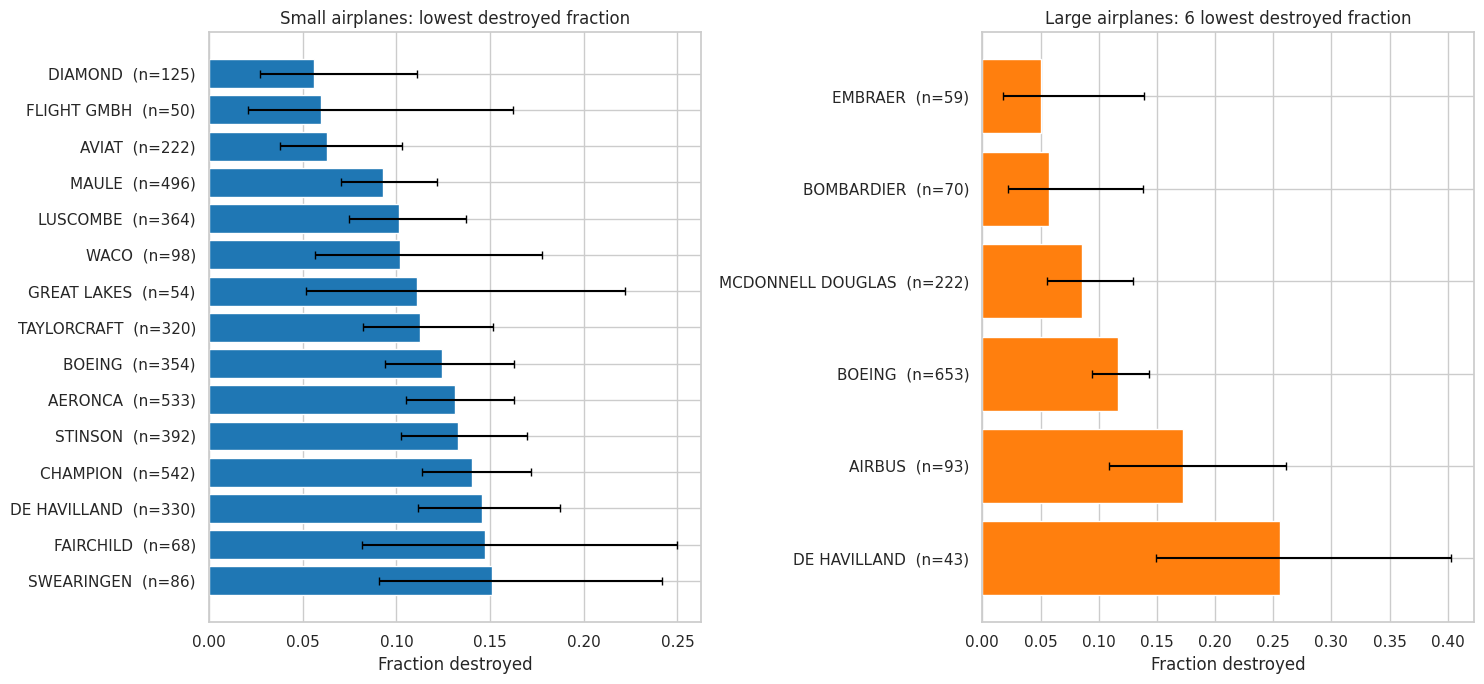

,Make,n,destroyed,d_lo,d_hi,mean_fs
13,DIAMOND,125,0.056,0.027,0.111,0.235
34,FLIGHT GMBH,50,0.060,0.021,0.162,0.370
8,AVIAT,222,0.063,0.038,0.103,0.200
3,MAULE,496,0.093,0.070,0.121,0.163
12,LUSCOMBE,364,0.102,0.075,0.137,0.228
0,WACO,98,0.102,0.056,0.178,0.131
1,GREAT LAKES,54,0.111,0.052,0.222,0.139
25,TAYLORCRAFT,320,0.112,0.082,0.152,0.302
5,BOEING,354,0.124,0.094,0.163,0.175
17,AERONCA,533,0.131,0.105,0.163,0.255


,Make,n,destroyed,d_lo,d_hi,mean_fs
2,EMBRAER,59,0.051,0.017,0.139,0.080
1,BOMBARDIER,70,0.057,0.022,0.138,0.062
0,MCDONNELL DOUGLAS,222,0.086,0.055,0.130,0.054
3,BOEING,653,0.116,0.094,0.143,0.113
4,AIRBUS,93,0.172,0.109,0.261,0.172
5,DE HAVILLAND,43,0.256,0.149,0.402,0.238


In [9]:
ds = small_makes.sort_values('destroyed').head(15)
dl = large_makes.sort_values('destroyed').head(15)
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
bar_with_ci(axes[0], ds, 'destroyed', 'd_lo', 'd_hi', 'tab:blue', 'Small airplanes: lowest destroyed fraction', 'Fraction destroyed')
bar_with_ci(axes[1], dl, 'destroyed', 'd_lo', 'd_hi', 'tab:orange', f'Large airplanes: {len(dl)} lowest destroyed fraction', 'Fraction destroyed')
plt.tight_layout(); save('makes_destroyed'); plt.show()
display(ds[['Make','n','destroyed','d_lo','d_hi','mean_fs']].round(3)); display(dl[['Make','n','destroyed','d_lo','d_hi','mean_fs']].round(3))

**Combining both measures** (makes ranked by the average of their injury-fraction rank and destroyed-fraction rank):

In [10]:
def combined(tbl):
    t = tbl.copy()
    t['rank_fs'] = t['mean_fs'].rank(); t['rank_d'] = t['destroyed'].rank()
    t['combined_rank'] = (t['rank_fs'] + t['rank_d']) / 2
    return t.sort_values('combined_rank')[['Make','n','mean_fs','destroyed','combined_rank']].round(3).reset_index(drop=True)
print('SMALL'); display(combined(small_makes).head(10))
print('LARGE'); display(combined(large_makes).head(10))

SMALL


,Make,n,mean_fs,destroyed,combined_rank
0,WACO,98,0.131,0.102,3.5
1,MAULE,496,0.163,0.093,4.0
2,GREAT LAKES,54,0.139,0.111,4.5
3,AVIAT,222,0.200,0.063,6.0
4,DIAMOND,125,0.235,0.056,7.5
5,BOEING,354,0.175,0.124,7.5
6,LUSCOMBE,364,0.228,0.102,9.0
7,SCHWEIZER,318,0.151,0.173,10.5
8,HELIO,69,0.166,0.159,11.0
9,SWEARINGEN,86,0.176,0.151,11.0


LARGE


,Make,n,mean_fs,destroyed,combined_rank
0,MCDONNELL DOUGLAS,222,0.054,0.086,2.0
1,BOMBARDIER,70,0.062,0.057,2.0
2,EMBRAER,59,0.080,0.051,2.0
3,BOEING,653,0.113,0.116,4.0
4,AIRBUS,93,0.172,0.172,5.0
5,DE HAVILLAND,43,0.238,0.256,6.0


### Are the differences between makes statistically real?
We compare each of the five best makes against a baseline (**Cessna** for small, **Boeing** for large, the biggest group in each class) with a Mann-Whitney U test and a Welch t-test on the difference in mean injury fraction, Bonferroni-corrected (Welch p only) for the five comparisons. We also run an overall Kruskal-Wallis test across all ranked makes.

In [11]:
def compare_to_baseline(data, tbl, baseline, k=5):
    base = data.loc[data['Make'] == baseline, 'fatal_serious_frac']
    rows = []
    for m in [x for x in tbl['Make'] if x != baseline][:k]:
        g = data.loc[data['Make'] == m, 'fatal_serious_frac']
        p = stats.mannwhitneyu(g, base).pvalue
        # Welch t-test on the difference in MEANS (Mann-Whitney is rank-based and blind to the heavy tail of fatal crashes)
        pm = stats.ttest_ind(g, base, equal_var=False).pvalue
        rows.append(dict(Make=m, n=len(g), mean=g.mean(), baseline_mean=base.mean(), p_mannwhitney=p,
                         p_welch_means=pm, p_welch_bonf=min(1, pm * k)))
    return pd.DataFrame(rows).round(4)

for name, data, tbl, base in [('SMALL vs CESSNA', small, small_makes, 'CESSNA'), ('LARGE vs BOEING', large, large_makes, 'BOEING')]:
    ranked = data[data['Make'].isin(tbl['Make'])]
    kw = stats.kruskal(*[g['fatal_serious_frac'].values for _, g in ranked.groupby('Make')]).pvalue
    print(f'{name}: Kruskal-Wallis across ranked makes p = {kw:.2e}')
    display(compare_to_baseline(data, tbl, base))


SMALL vs CESSNA: Kruskal-Wallis across ranked makes p = 5.87e-141


,Make,n,mean,baseline_mean,p_mannwhitney,p_welch_means,p_welch_bonf
0,WACO,98,0.1310,0.2412,0.0077,0.0012,0.0058
1,GREAT LAKES,54,0.1389,0.2412,0.0501,0.0327,0.1636
2,SCHWEIZER,318,0.1515,0.2412,0.0000,0.0000,0.0001
3,MAULE,496,0.1632,0.2412,0.0000,0.0000,0.0000
4,HELIO,69,0.1657,0.2412,0.1717,0.0846,0.4231


LARGE vs BOEING: Kruskal-Wallis across ranked makes p = 2.42e-02


,Make,n,mean,baseline_mean,p_mannwhitney,p_welch_means,p_welch_bonf
0,MCDONNELL DOUGLAS,222,0.0541,0.1126,0.8392,0.0008,0.0039
1,BOMBARDIER,70,0.0622,0.1126,0.2976,0.0829,0.4146
2,EMBRAER,59,0.0800,0.1126,0.8804,0.3461,1.0000
3,AIRBUS,93,0.1724,0.1126,0.0124,0.1330,0.6650
4,DE HAVILLAND,43,0.2385,0.1126,0.0387,0.0479,0.2394


### Discussion: makes

**Small airplanes (42 makes with 50+ records; 54,656 accident records)**
- The lowest mean fatal/serious fractions belong to **Waco (0.131, n=98), Great Lakes (0.139, n=54), Schweizer (0.151, n=318), Maule (0.163, n=496), Helio (0.166, n=69)** and Boeing-labelled small planes (0.175, n=354; these are mostly Stearman biplanes). The biggest brand in the data, **Cessna, averages 0.241 (n=24,847)**.
- The lowest *destroyed* fractions are **Diamond (5.6%), Aviat (6.3%), Maule (9.3%), Luscombe, Waco (10.2%)**, compared with about 19% for Cessna.
- Combining both rankings, the most consistent performers are **Waco, Maule, Great Lakes, Aviat, Diamond** (Maule is in the top 5 for both measures, and has a large sample of 496).
- **Statistical support:** the makes differ overall (Kruskal-Wallis p ~ 1e-141). Against Cessna, **Maule, Schweizer, Waco and Boeing/Stearman are significantly lower** on injury fraction even after Bonferroni correction (corrected Welch p < 0.01). **Great Lakes and Helio are not significantly different** (their samples of 54 and 69 are too small), so we do not recommend them on injury evidence alone.
- The distributions show why means can mislead: for every one of these makes about 77-85% of accidents have *zero* fatal/serious injuries, and 11-20% have *everyone* seriously hurt or killed. The mean mostly reflects the mix of those two outcomes.
- **Caveat:** many of the best-ranked small makes are antique/aerobatic/utility aircraft that mostly fly with 1-2 people aboard, so the fraction is close to 0 or 1 per accident. Their results are real but not necessarily transferable to a typical four-seat touring aircraft.

**Large airplanes (6 makes with 20+ records; 1,142 accident records)**
- Lowest injury fractions: **McDonnell Douglas (0.054, n=222), Bombardier (0.062, n=70), Embraer (0.080, n=59)**, then Boeing (0.113, n=653), Airbus (0.172, n=93), De Havilland (0.238, n=43).
- Lowest destroyed fractions: **Embraer (5.1%), Bombardier (5.7%), McDonnell Douglas (8.6%)**, Boeing 11.6%, Airbus 17.2%, De Havilland 25.6%.
- Evidence strength is **moderate**: the overall difference across large makes is significant (Kruskal-Wallis p = 0.024). **McDonnell Douglas is significantly lower than Boeing on mean injury fraction** (Bonferroni-corrected Welch p = 0.004; the 95% intervals do not overlap: 0.031-0.082 vs 0.090-0.135). Bombardier and Embraer have the same low point estimates but wide intervals (n=70, 59), so they are **not** statistically distinguishable from Boeing. Airbus and De Havilland look worse, but after correction the gap to Boeing is not significant.
- Large-aircraft accidents are mostly benign (67-84% have zero fatal/serious injuries) with a small share of catastrophic events (2-14% with everyone seriously hurt or killed). Means are driven by those rare events, which is why intervals are wide.
- **Business caveat:** several McDonnell Douglas types in the sample (DC-9, MD-80 series, DC-10, MD-11) are older designs that have been retired or are being retired from passenger service; the client should confirm which are still active before relying on those results.

## Analyze plane types (make + model)
**Rule:** only plane types with **at least 10 accident records** are ranked. For the final shortlists below we additionally flag types with **30 or more** records as more statistically reliable (a mean built on 10 records is noisy, especially when many records are 0 or 1).

In [12]:
def type_table(data, min_n):
    rows = []
    for t, g in data.groupby('plane_type'):
        if len(g) < min_n: continue
        lo, hi = boot_ci(g['fatal_serious_frac'], n_boot=1000)
        dl_, dh_ = wilson(g['destroyed'].sum(), len(g))
        rows.append(dict(plane_type=t, Make=g['Make'].iloc[0], n=len(g), mean_fs=g['fatal_serious_frac'].mean(),
                         fs_lo=lo, fs_hi=hi, destroyed=g['destroyed'].mean(), d_lo=dl_, d_hi=dh_))
    return pd.DataFrame(rows).sort_values('mean_fs').reset_index(drop=True)

small_types = type_table(small, 10)
large_types = type_table(large, 10)
print('Small types (n>=10):', len(small_types), '| Large types (n>=10):', len(large_types))

Small types (n>=10): 640 | Large types (n>=10): 34


**Larger planes**

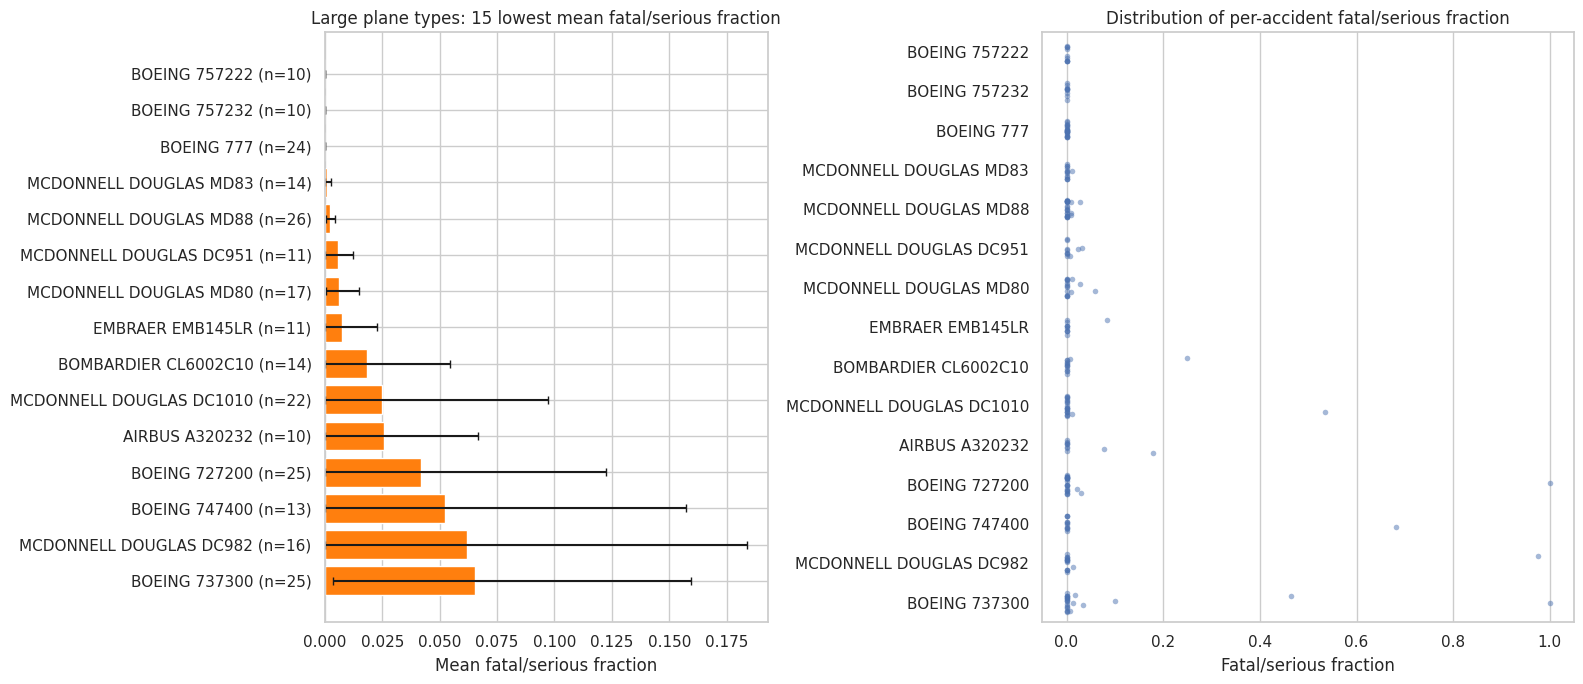

,plane_type,Make,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,BOEING 757222,BOEING,10,0.000,0.000,0.000,0.000,0.000,0.278
1,BOEING 757232,BOEING,10,0.000,0.000,0.000,0.000,0.000,0.278
2,BOEING 777,BOEING,24,0.000,0.000,0.000,0.042,0.007,0.202
3,MCDONNELL DOUGLAS MD83,MCDONNELL DOUGLAS,14,0.001,0.000,0.003,0.071,0.013,0.315
4,MCDONNELL DOUGLAS MD88,MCDONNELL DOUGLAS,26,0.002,0.000,0.005,0.000,0.000,0.129
5,MCDONNELL DOUGLAS DC951,MCDONNELL DOUGLAS,11,0.006,0.000,0.012,0.091,0.016,0.377
6,MCDONNELL DOUGLAS MD80,MCDONNELL DOUGLAS,17,0.006,0.001,0.015,0.000,0.000,0.184
7,EMBRAER EMB145LR,EMBRAER,11,0.008,0.000,0.023,0.000,0.000,0.259
8,BOMBARDIER CL6002C10,BOMBARDIER,14,0.018,0.000,0.055,0.000,0.000,0.215
9,MCDONNELL DOUGLAS DC1010,MCDONNELL DOUGLAS,22,0.025,0.000,0.097,0.045,0.008,0.218


In [13]:
top_lt = large_types.head(15)
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.2]})
t = top_lt.iloc[::-1]
axes[0].barh(t['plane_type'] + ' (n=' + t['n'].astype(str) + ')', t['mean_fs'],
             xerr=[t['mean_fs'] - t['fs_lo'], t['fs_hi'] - t['mean_fs']], capsize=3, color='tab:orange')
axes[0].set_title('Large plane types: 15 lowest mean fatal/serious fraction'); axes[0].set_xlabel('Mean fatal/serious fraction')
order_lt = top_lt['plane_type'].tolist()
sns.stripplot(data=large[large['plane_type'].isin(order_lt)], y='plane_type', x='fatal_serious_frac', order=order_lt,
              alpha=0.5, size=4, jitter=0.25, ax=axes[1])
axes[1].set_title('Distribution of per-accident fatal/serious fraction'); axes[1].set_xlabel('Fatal/serious fraction'); axes[1].set_ylabel('')
plt.tight_layout(); save('large_types'); plt.show()
display(top_lt.round(3))

**Smaller planes** (10 lowest mean fatal/serious fraction, n >= 10)

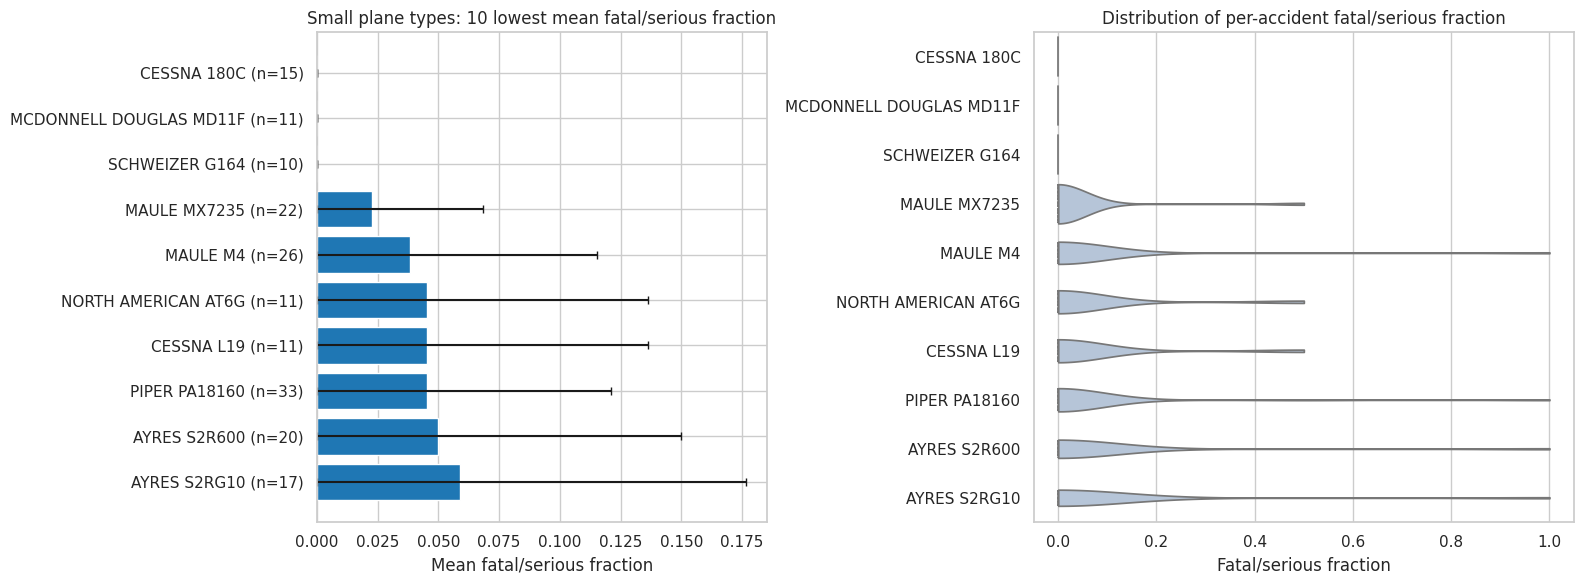

,plane_type,Make,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,CESSNA 180C,CESSNA,15,0.000,0.0,0.000,0.067,0.012,0.298
1,MCDONNELL DOUGLAS MD11F,MCDONNELL DOUGLAS,11,0.000,0.0,0.000,0.091,0.016,0.377
2,SCHWEIZER G164,SCHWEIZER,10,0.000,0.0,0.000,0.000,0.000,0.278
3,MAULE MX7235,MAULE,22,0.023,0.0,0.068,0.000,0.000,0.149
4,MAULE M4,MAULE,26,0.038,0.0,0.115,0.038,0.007,0.189
5,NORTH AMERICAN AT6G,NORTH AMERICAN,11,0.045,0.0,0.136,0.000,0.000,0.259
6,CESSNA L19,CESSNA,11,0.045,0.0,0.136,0.091,0.016,0.377
7,PIPER PA18160,PIPER,33,0.045,0.0,0.121,0.030,0.005,0.153
8,AYRES S2R600,AYRES,20,0.050,0.0,0.150,0.200,0.081,0.416
9,AYRES S2RG10,AYRES,17,0.059,0.0,0.176,0.176,0.062,0.410


In [14]:
top_st = small_types.head(10)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.2]})
t = top_st.iloc[::-1]
axes[0].barh(t['plane_type'] + ' (n=' + t['n'].astype(str) + ')', t['mean_fs'],
             xerr=[t['mean_fs'] - t['fs_lo'], t['fs_hi'] - t['mean_fs']], capsize=3, color='tab:blue')
axes[0].set_title('Small plane types: 10 lowest mean fatal/serious fraction'); axes[0].set_xlabel('Mean fatal/serious fraction')
order_st = top_st['plane_type'].tolist()
sns.violinplot(data=small[small['plane_type'].isin(order_st)], y='plane_type', x='fatal_serious_frac', order=order_st,
               cut=0, inner='quartile', color='lightsteelblue', ax=axes[1])
axes[1].set_title('Distribution of per-accident fatal/serious fraction'); axes[1].set_xlabel('Fatal/serious fraction'); axes[1].set_ylabel('')
plt.tight_layout(); save('small_types'); plt.show()
display(top_st.round(3))

**More reliable shortlists** (small: n >= 30; large: n >= 20 because large types have fewer records), ranked by the *upper* 95% confidence bound of the mean fatal/serious fraction (a conservative ranking: it rewards low means with tight intervals):

In [15]:
def shortlist(types, min_n=30, k=10):
    # min_n is set per size class below (small: 30, large: 20 because large types are rarer)
    t = types[types['n'] >= min_n].copy()
    return t.sort_values('fs_hi').head(k)[['plane_type', 'n', 'mean_fs', 'fs_lo', 'fs_hi', 'destroyed', 'd_lo', 'd_hi']].round(3).reset_index(drop=True)
print('SMALL (n>=30)'); display(shortlist(small_types))
print('LARGE (n>=20)'); display(shortlist(large_types, min_n=20))

SMALL (n>=30)


,plane_type,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,PIPER PA18160,33,0.045,0.000,0.121,0.030,0.005,0.153
1,PIPER PA20,132,0.080,0.038,0.129,0.053,0.026,0.105
2,CESSNA 180,593,0.111,0.087,0.135,0.078,0.059,0.102
3,CESSNA 185F,100,0.083,0.040,0.136,0.090,0.048,0.162
4,CESSNA 180A,56,0.071,0.018,0.143,0.036,0.010,0.121
5,CESSNA 185E,35,0.076,0.011,0.147,0.057,0.016,0.186
6,CESSNA A185E,63,0.088,0.035,0.151,0.032,0.009,0.109
7,CESSNA 185,264,0.123,0.088,0.162,0.098,0.068,0.140
8,GRUMMAN G164A,356,0.126,0.096,0.166,0.225,0.184,0.271
9,BOEING E75,33,0.076,0.000,0.167,0.121,0.048,0.273


LARGE (n>=20)


,plane_type,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,BOEING 777,24,0.000,0.000,0.000,0.042,0.007,0.202
1,MCDONNELL DOUGLAS MD88,26,0.002,0.000,0.005,0.000,0.000,0.129
2,MCDONNELL DOUGLAS DC1010,22,0.025,0.000,0.097,0.045,0.008,0.218
3,BOEING 727200,25,0.042,0.000,0.122,0.040,0.007,0.195
4,BOEING 737300,25,0.066,0.003,0.159,0.120,0.042,0.300
5,BOEING 747,31,0.068,0.000,0.164,0.065,0.018,0.207
6,BOMBARDIER CL6002B19,37,0.076,0.003,0.165,0.081,0.028,0.213
7,BOEING 737,121,0.134,0.080,0.192,0.107,0.064,0.175
8,MCDONNELL DOUGLAS MD11,31,0.112,0.030,0.209,0.161,0.071,0.326
9,BOEING 767,23,0.100,0.005,0.226,0.130,0.045,0.321


### Discussion: specific airplane types

**Small airplane types** (640 types with 10+ records)
- Among types with the lowest means, many have a perfect 0.00 on only 10-15 records (Cessna 180C, Schweizer G164). With so few records the confidence intervals are wide, so we treat those as *leads* only. Note that "MD-11F" shows up as small only because freighter accidents usually carry just the crew; it is not a passenger recommendation.
- With the stricter **n >= 30** shortlist, the types with the best evidence are the **Piper PA-18-160 (Super Cub; 0.045, n=33), Piper PA-20 (0.080, n=132; destroyed 5.3%), Cessna 180 (0.111, n=593), Cessna 185F/185E/A185E and Cessna 180A (all 0.07-0.09)** and the **Maule M-4 / MX-7-235** (0.04 and 0.02, n=26 and 22; promising but under the n=30 bar).
- The **Cessna 180/185 and Piper Cub-family** types show low injury *and* low destruction (3-10% destroyed).
- Agricultural types (**Grumman G-164A Ag-Cat, Ayres S2R**) have low injury fractions (about 0.05-0.13) but **high destruction (18-23%)**. For an insurer exposed to hull losses, low injury does not mean low cost; the two measures must be read together.

**Large airplane types** (34 types with 10+ records)
- Lowest means (n >= 10): Boeing 757-222 and 757-232 (0.00, n=10 each), **Boeing 777 (0.000, n=24; destroyed 4.2%)**, **MD-83 / MD-88 / MD-80** (<= 0.006), Embraer EMB-145LR, Bombardier CL-600-2C10 (0.018, n=14), DC-10-10 (0.025, n=22), Airbus A320-232 (0.026, n=10).
- The more reliable shortlist (n >= 20) ranked by the *upper* confidence bound: **Boeing 777, McDonnell Douglas MD-88, DC-10-10, Boeing 727-200, 737-300, 747, Bombardier CL-600-2B19 (CRJ-200 family; n=37; 0.076)**. The high-volume **Boeing 737 (n=121)** averages 0.134 (95% CI 0.080-0.192), which is a good sign of typical large-jet outcomes rather than an outlier.
- **Reading the zeros:** a type with 10 accidents and a mean of 0 is not proof of safety (the true rate could still be sizeable). We therefore weight types with 20+ records and note that no single large type is statistically separable from the group at the type level; the **make-level** results are the better basis for decisions, and the type results show which products within them are performing well.
- **Practical recommendation:** for large aircraft favor **Boeing 777/757, McDonnell Douglas MD-80 series, and Bombardier/Embraer regional jets** (subject to active-fleet checks); treat **Airbus** and **De Havilland** types as higher-severity in this data, with weaker statistical certainty.

## Exploring other variables
We analyze four factors: **Weather Condition**, **Phase of Flight**, **Number of Engines**, **Engine Type**. For each, groups with fewer than 30 records are not compared. Each analysis reports n, mean fatal/serious fraction with 95% CI, destroyed rate with Wilson 95% CI, and a significance test. Because the small and large fleets differ so much, results are shown **by size class**.

In [16]:
def factor_summary(data, col, min_n=30):
    rows = []
    for lvl, g in data.dropna(subset=[col]).groupby(col):
        if len(g) < min_n: continue
        sem = g['fatal_serious_frac'].std(ddof=1) / np.sqrt(len(g))
        dl_, dh_ = wilson(g['destroyed'].sum(), len(g))
        rows.append({col: lvl, 'n': len(g), 'mean_fs': g['fatal_serious_frac'].mean(),
                     'fs_lo': max(0, g['fatal_serious_frac'].mean() - 1.96*sem), 'fs_hi': g['fatal_serious_frac'].mean() + 1.96*sem,
                     'destroyed': g['destroyed'].mean(), 'd_lo': dl_, 'd_hi': dh_})
    return pd.DataFrame(rows)

def tests(data, col, min_n=30):
    d = data.dropna(subset=[col])
    d = d[d[col].map(d[col].value_counts()) >= min_n]
    groups = [g['fatal_serious_frac'].values for _, g in d.groupby(col)]
    if len(groups) == 2:
        p_fs = stats.mannwhitneyu(*groups).pvalue; name = 'Mann-Whitney U'
    else:
        p_fs = stats.kruskal(*groups).pvalue; name = 'Kruskal-Wallis'
    chi2, p_d, _, _ = stats.chi2_contingency(pd.crosstab(d[col], d['destroyed']))
    return f'{name} (fatal/serious fraction) p = {p_fs:.2e};  chi-square (destroyed) p = {p_d:.2e}'

def plot_factor(col, order=None, rot=0):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for i, (name, data) in enumerate([('Small', small), ('Large', large)]):
        s = factor_summary(data, col)
        if order: s = s.set_index(col).reindex([o for o in order if o in set(s[col])]).reset_index()
        x = s[col].astype(str) + '\n(n=' + s['n'].astype(str) + ')'
        axes[0, i].bar(x, s['mean_fs'], yerr=[s['mean_fs'] - s['fs_lo'], s['fs_hi'] - s['mean_fs']], capsize=4, color='tab:blue' if i == 0 else 'tab:orange')
        axes[0, i].set_title(f'{name}: mean fatal/serious fraction by {col}'); axes[0, i].set_ylim(bottom=0)
        axes[1, i].bar(x, s['destroyed'], yerr=[s['destroyed'] - s['d_lo'], s['d_hi'] - s['destroyed']], capsize=4, color='tab:blue' if i == 0 else 'tab:orange')
        axes[1, i].set_title(f'{name}: fraction destroyed by {col}'); axes[1, i].set_ylim(bottom=0)
        for a in (axes[0, i], axes[1, i]): a.tick_params(axis='x', rotation=rot)
    plt.tight_layout(); save('factor_' + col.replace('.', '_') + ''); plt.show()
    for name, data in [('Small', small), ('Large', large)]:
        print(f'{name}: ', tests(data, col))
        display(factor_summary(data, col).round(3))

### Factor 1: Weather condition (VMC = visual conditions, IMC = instrument conditions)

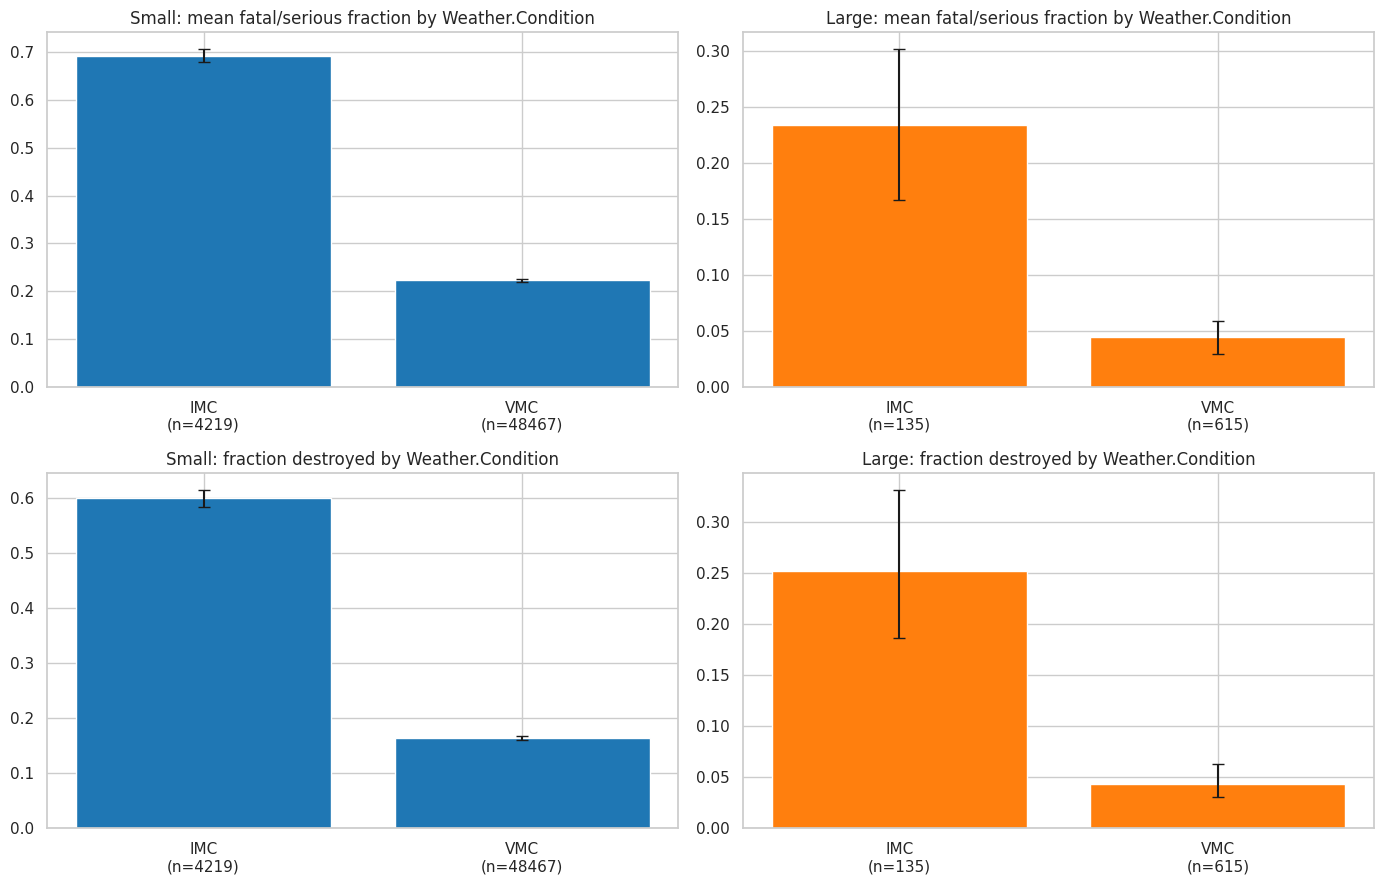

Small:  Mann-Whitney U (fatal/serious fraction) p = 0.00e+00;  chi-square (destroyed) p = 0.00e+00


,Weather.Condition,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,IMC,4219,0.691,0.678,0.705,0.599,0.584,0.613
1,VMC,48467,0.223,0.220,0.227,0.165,0.161,0.168


Large:  Mann-Whitney U (fatal/serious fraction) p = 2.28e-14;  chi-square (destroyed) p = 4.87e-15


,Weather.Condition,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,IMC,135,0.234,0.167,0.302,0.252,0.186,0.331
1,VMC,615,0.045,0.030,0.059,0.044,0.030,0.063


In [17]:
plot_factor('Weather.Condition')

**Findings.** Weather is the strongest single factor we measured. In instrument conditions (IMC) accidents are far more severe:

| | Fatal/serious fraction (95% CI) | Destroyed |
|---|---|---|
| Small, VMC (n=48,467) | 0.223 (0.220-0.227) | 16.5% |
| Small, IMC (n=4,219) | **0.691 (0.678-0.705)** | **59.9%** |
| Large, VMC (n=615) | 0.045 (0.030-0.059) | 4.4% |
| Large, IMC (n=135) | **0.234 (0.167-0.302)** | **25.2%** |

IMC accidents have about **3x** the injury fraction for small planes and **5x** for large planes, and destruction is **3.6x / 5.7x** as likely. The confidence intervals do not overlap and both tests are decisive (small: p ~ 0; large: p ~ 1e-14). **Interpretation:** accidents in poor visibility are often loss-of-control or flight-into-terrain events at high energy with little chance of survival, whereas VMC accidents include many low-speed landing mishaps. **Caveat:** these are accident-only data; we cannot say IMC flying has a higher *accident rate*, only that accidents in IMC are much worse. Insurer implication: IMC-capable crews, equipment and operating policies drive loss severity.

### Factor 2: Phase of flight

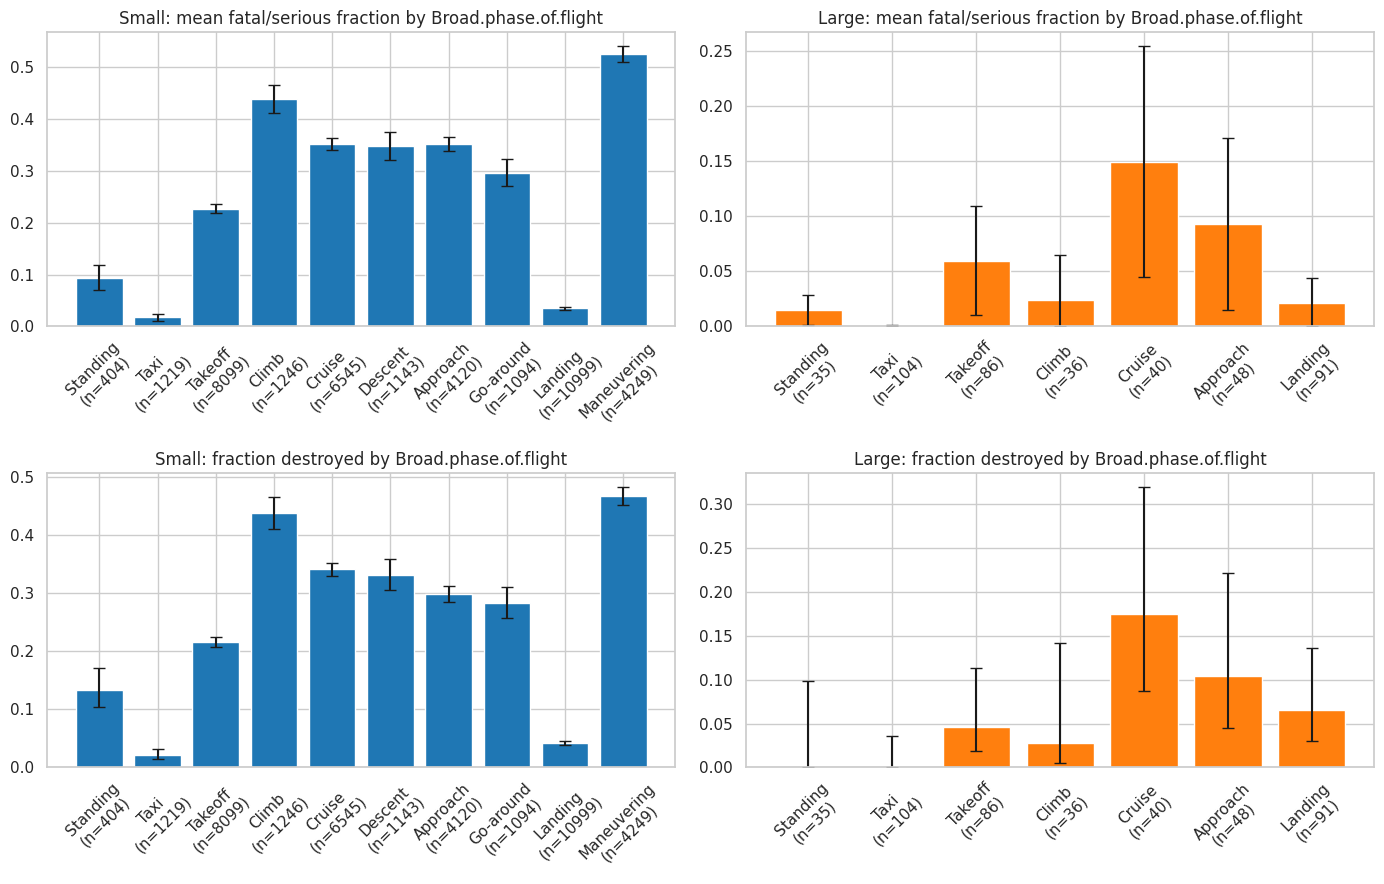

Small:  Kruskal-Wallis (fatal/serious fraction) p = 0.00e+00;  chi-square (destroyed) p = 0.00e+00


,Broad.phase.of.flight,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,Approach,4120,0.352,0.338,0.366,0.298,0.284,0.312
1,Climb,1246,0.439,0.412,0.465,0.438,0.411,0.466
2,Cruise,6545,0.352,0.341,0.364,0.341,0.330,0.353
3,Descent,1143,0.348,0.321,0.374,0.332,0.305,0.359
4,Go-around,1094,0.297,0.271,0.323,0.283,0.257,0.311
5,Landing,10999,0.035,0.032,0.038,0.042,0.038,0.046
6,Maneuvering,4249,0.526,0.511,0.540,0.467,0.452,0.482
7,Standing,404,0.094,0.069,0.118,0.134,0.104,0.170
8,Takeoff,8099,0.227,0.218,0.235,0.216,0.207,0.225
9,Taxi,1219,0.017,0.011,0.024,0.022,0.015,0.032


Large:  Kruskal-Wallis (fatal/serious fraction) p = 5.86e-07;  chi-square (destroyed) p = 7.10e-04


,Broad.phase.of.flight,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,Approach,48,0.093,0.015,0.171,0.104,0.045,0.222
1,Climb,36,0.024,0.000,0.065,0.028,0.005,0.142
2,Cruise,40,0.150,0.045,0.254,0.175,0.087,0.320
3,Landing,91,0.021,0.000,0.044,0.066,0.031,0.136
4,Standing,35,0.015,0.001,0.029,0.000,0.000,0.099
5,Takeoff,86,0.060,0.010,0.109,0.047,0.018,0.114
6,Taxi,104,0.001,0.000,0.001,0.000,0.000,0.036


In [18]:
phase_order = ['Standing', 'Taxi', 'Takeoff', 'Climb', 'Cruise', 'Descent', 'Approach', 'Go-around', 'Landing', 'Maneuvering']
plot_factor('Broad.phase.of.flight', order=phase_order, rot=45)

**Findings.** Severity depends heavily on the phase of flight (small: Kruskal-Wallis p < 1e-100; large: p = 6e-7).

- **Small planes:** most severe in **Maneuvering (fatal/serious 0.526; 46.7% destroyed), Climb (0.439; 43.8%), Cruise (0.352), Approach (0.352) and Descent (0.348)**. Mild in **Landing (0.035; 4.2% destroyed; n=10,999)** and **Taxi (0.017)**, with Takeoff in between (0.227).
- **Large planes:** same pattern but with smaller samples (35-104 per phase): **Cruise (0.150, n=40)** and **Approach (0.093, n=48)** are worst, while **Landing (0.021), Climb, Standing and Taxi** are near zero. Intervals overlap among adjacent phases, so only the broad split (airborne cruise/approach vs ground/landing phases) is solid.
- **Interpretation:** landing is the most *frequent* accident phase but the least severe because speeds and altitude are low; maneuvering and climb accidents (low altitude, stalls, loss of control) are the most lethal. Phase is a confounder for any make comparison: a make heavily used for aerial application or aerobatics will show more maneuvering accidents and worse averages. About 29% of rows lack a phase and were excluded here.

### Factor 3: Number of engines

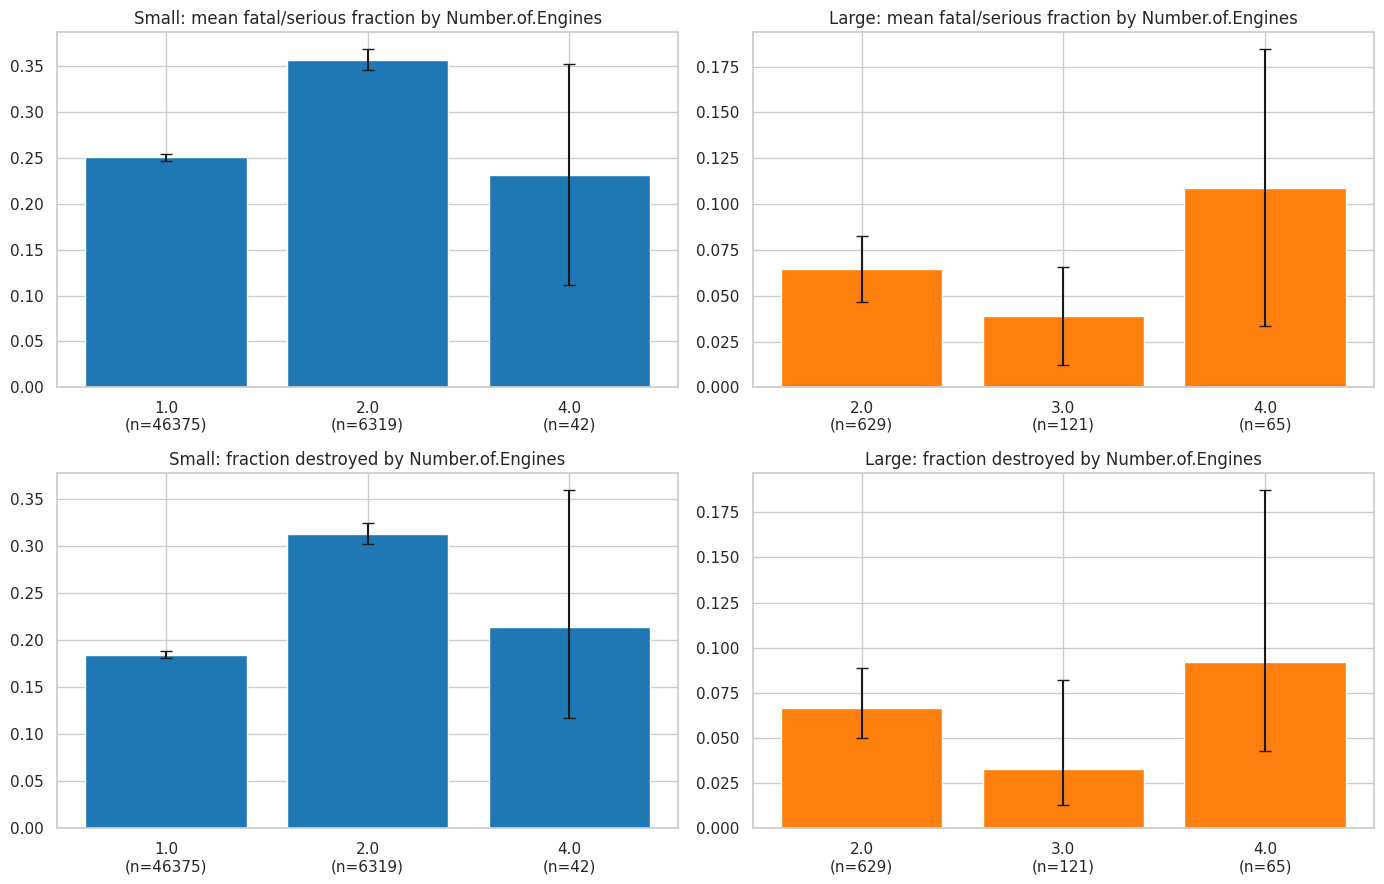

Small:  Kruskal-Wallis (fatal/serious fraction) p = 4.23e-76;  chi-square (destroyed) p = 1.20e-125


,Number.of.Engines,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,1.0,46375,0.250,0.247,0.254,0.185,0.181,0.188
1,2.0,6319,0.357,0.345,0.368,0.313,0.302,0.325
2,4.0,42,0.232,0.112,0.352,0.214,0.117,0.359


Large:  Kruskal-Wallis (fatal/serious fraction) p = 8.66e-01;  chi-square (destroyed) p = 2.36e-01


,Number.of.Engines,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,2.0,629,0.065,0.047,0.082,0.067,0.050,0.089
1,3.0,121,0.039,0.012,0.065,0.033,0.013,0.082
2,4.0,65,0.109,0.033,0.184,0.092,0.043,0.187


In [19]:
plot_factor('Number.of.Engines')

**Findings.**
- **Small planes:** twin-engine accidents are *worse* than single-engine: fatal/serious **0.357 vs 0.250**, destroyed **31.3% vs 18.5%** (both p < 1e-70, n=6,319 vs 46,375). The 4-engine small group (n=42) is too small to conclude anything.
- **Large planes:** no meaningful difference between 2-, 3- and 4-engine aircraft (0.065, 0.039, 0.109; Kruskal-Wallis p = 0.87; destroyed chi-square p = 0.24). Having more engines does not show a measurable survivability benefit once an accident happens.
- **Interpretation:** small twins are faster, higher-performance and more complex, and engine-out handling plus higher impact energy can offset the redundancy benefit. These explanations are plausible but not tested here.

### Factor 4: Engine type

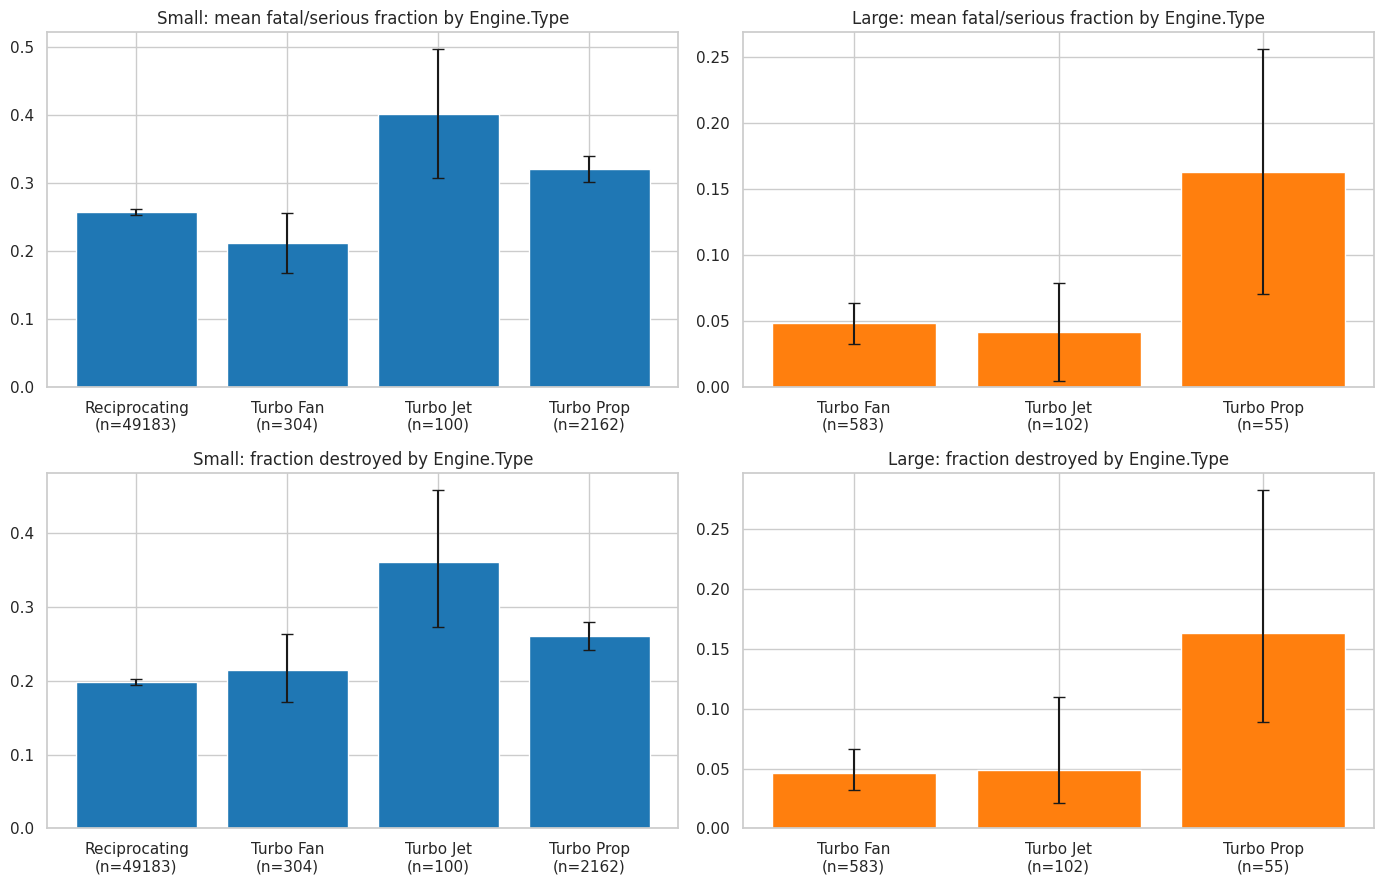

Small:  Kruskal-Wallis (fatal/serious fraction) p = 9.08e-14;  chi-square (destroyed) p = 4.51e-14


,Engine.Type,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,Reciprocating,49183,0.258,0.254,0.261,0.198,0.195,0.202
1,Turbo Fan,304,0.212,0.168,0.256,0.214,0.171,0.263
2,Turbo Jet,100,0.402,0.307,0.497,0.360,0.273,0.458
3,Turbo Prop,2162,0.321,0.302,0.340,0.260,0.242,0.279


Large:  Kruskal-Wallis (fatal/serious fraction) p = 2.36e-01;  chi-square (destroyed) p = 1.29e-03


,Engine.Type,n,mean_fs,fs_lo,fs_hi,destroyed,d_lo,d_hi
0,Turbo Fan,583,0.049,0.033,0.064,0.046,0.032,0.067
1,Turbo Jet,102,0.042,0.005,0.079,0.049,0.021,0.110
2,Turbo Prop,55,0.163,0.071,0.256,0.164,0.089,0.283


In [20]:
plot_factor('Engine.Type')

**Findings.**
- **Small planes:** significant differences (p ~ 1e-13). Turbofan is lowest (0.212, n=304), reciprocating is 0.258 (n=49,183), turboprop 0.321 (n=2,162) and **turbojet worst at 0.402 (destroyed 36%, n=100)**.
- **Large planes:** the injury fraction does not differ significantly (p = 0.24; turbofan 0.049, turbojet 0.042, turboprop 0.163), but destroyed rates do (p = 0.0013; **turboprop 16.4% vs ~5% for jets**). Turboprop's group is small (n=55), so the intervals are wide.
- **Interpretation:** engine type is entangled with aircraft class and mission (turboprops are regional/commuter aircraft, small jets are high-performance business aircraft), so it should be used as a context variable rather than a stand-alone buying criterion.

### Is the engine-count effect just a size effect?
Single vs. twin-engine planes differ in size, mission and pilot experience. Within the Small class, compare 1 vs 2 engines under both weather conditions to check whether the difference persists:

In [21]:
s2 = small[small['Number.of.Engines'].isin([1, 2]) & small['Weather.Condition'].notna()]
print(s2.groupby(['Weather.Condition', 'Number.of.Engines']).agg(
    n=('destroyed', 'size'), mean_fs=('fatal_serious_frac', 'mean'), destroyed=('destroyed', 'mean')).round(3))

                                         n  mean_fs  destroyed
Weather.Condition Number.of.Engines                           
IMC               1.0                 2873    0.722      0.614
                  2.0                 1214    0.603      0.550
VMC               1.0                42657    0.211      0.151
                  2.0                 4848    0.284      0.247


**Result.** The twin-vs-single difference is **not a pure size or weather effect**, and it flips with conditions:
- **VMC:** twins are worse (0.284 vs 0.211 fatal/serious; destroyed 24.7% vs 15.1%).
- **IMC:** twins are somewhat *better* (0.603 vs 0.722; destroyed 55.0% vs 61.4%).

So the extra engine seems to help in difficult weather (e.g. more power/redundancy and typically more capable, instrument-equipped aircraft and crews) but not in good-weather accidents. Whatever the explanation, weather matters far more than engine count: the weather gap (0.22 to 0.69) dwarfs the engine gap.

## Summary and recommendations for the client

**Small aircraft (under ~20 people aboard)**
1. **Maule** is the most consistent make: top-5 on both injury (0.163) and destruction (9.3%), n=496, and significantly better than Cessna on injury.
2. **Aviat** and **Diamond** have the lowest destruction rates (about 6%), with average injury outcomes.
3. **Waco** and **Schweizer** have significantly lower injury fractions but are niche (antique/special-use) types.
4. Types with the best evidence (n >= 30): **Piper PA-18 (Super Cub), Piper PA-20, Cessna 180/185 family**.
5. Be cautious with agricultural types (Grumman G-164A, Ayres): low injury but high destruction.

**Large aircraft (20+ people aboard)**
1. **McDonnell Douglas** (MD-80 series, DC-10) has the lowest injury fraction and is significantly lower than Boeing; confirm which types are still active.
2. **Bombardier and Embraer regional jets** have low injury and destruction (5-8%) but small samples, so confidence is moderate.
3. **Boeing** (777, 757, 737/727 variants) is the best-evidenced large make (n=653) at 0.113 with 11.6% destroyed.
4. **Airbus** (0.172) and **De Havilland** (0.238) look riskier in this data, but evidence is limited (n=93, n=43).

**General factors (both with strong statistical support)**
- **Weather:** IMC accidents are 3-5x more severe in injury and 3.6-5.7x more likely to destroy the aircraft.
- **Phase of flight:** maneuvering, climb and cruise accidents are the most severe; landing and taxi are mild. Engine count/type effects exist for small aircraft (twin and turbojet worse) but are weaker and confounded.

**Limitations.** (1) Accident-only data: no exposure (flight hours/departures), so these are *severity* results, not accident-frequency results. (2) The injury fraction counts everyone aboard and is not split between crew and passengers. (3) Many small groups have wide confidence intervals; we flag them rather than rank on them. (4) Records are dominated by US events. (5) Several recommended types may be near end of service life.